# 01 · Exploratory analysis

Step 6 of the plan. Each section tests an assumption one of the models relies on.
Exploration only: final figure code moves to `src/figures.py`. Everything is computed from
`data/processed` (built by `python -m src.build_tables`). Intervals are 90% (exact Poisson /
Clopper-Pearson), matching CONVENTIONS.md.

1. **Power play:** does PWHL power-play scoring front-load after No Escape? How big is the 4-on-3 multiplier?
2. **Penalty shot:** shootout success by league, sample sizes, and how much of shooting is skill.
3. **Overtime:** 3-on-3 scoring rates, whether the OT goal hazard is flat, and when OT penalties happen.
4. **Sanity checks:** preseason and incomplete NHL games.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P, I = ROOT / "data" / "processed", ROOT / "data" / "interim"
FIG = ROOT / "outputs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

so = pd.read_parquet(P / "shootout_attempts.parquet")
pp = pd.read_parquet(P / "pp_intervals.parquet")
ot = pd.read_parquet(P / "ot_intervals.parquet")
otp = pd.read_parquet(P / "ot_penalties.parquet")
pd.set_option("display.width", 160)

# Chart style: reference palette (validated categorical slots), recessive axes and grid.
BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"
INK, MUTED, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 12, "axes.titlesize": 14,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})


def rate60(goals, seconds, level=0.90):
    """Goals per 60 minutes with an exact Poisson interval."""
    a = (1 - level) / 2
    lo = stats.chi2.ppf(a, 2 * goals) / 2 if goals > 0 else 0.0
    hi = stats.chi2.ppf(1 - a, 2 * goals + 2) / 2
    k = 3600 / seconds
    return goals * k, lo * k, hi * k


def prop_ci(k, n, level=0.90):
    """Proportion with a Clopper-Pearson interval."""
    a = (1 - level) / 2
    lo = stats.beta.ppf(a, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a, k + 1, n - k) if k < n else 1.0
    return k / n, lo, hi


def fmt(est, lo, hi, pct=False):
    return f"{est:.1%} [{lo:.1%}, {hi:.1%}]" if pct else f"{est:.2f} [{lo:.2f}, {hi:.2f}]"

## 1. Power play

### 1a. Does scoring front-load after No Escape?

Regulation 5-on-4 time only. "Pre" is the PWHL's 2024 season (no rule); "post" is 2024-25 on;
preseason is left out. The NHL has no such rule and is the reference shape. Time is measured
from the start of the power play; goals are rated per minute of exposure in each 30-second bin.

In [2]:
EDGES = np.array([0, 30, 60, 90, 120])
five4 = pp[(pp["strength"] == "5v4") & (pp["in_ot"] == 0) & (pp["season_type"] != "preseason")
           & (pp["goals_complete"] == 1)].copy()
five4["group"] = np.select(
    [five4["league"] == "NHL", five4["no_escape"] == 0], ["NHL", "PWHL pre (2024)"], "PWHL post (2024-25 on)")
GROUPS = ["PWHL pre (2024)", "PWHL post (2024-25 on)", "NHL"]
COLORS = {"PWHL pre (2024)": ORANGE, "PWHL post (2024-25 on)": BLUE, "NHL": MUTED}


def by_bin(df):
    a = df["spell_offset_s"].to_numpy()
    b = a + df["duration_s"].to_numpy()
    goal_t = df["first_goal_for_s"].to_numpy()
    out = []
    for lo, hi in zip(EDGES[:-1], EDGES[1:]):
        exposure = np.clip(np.minimum(b, hi) - np.maximum(a, lo), 0, None).sum()
        goals = int(((goal_t > lo) & (goal_t <= hi)).sum())
        out.append((f"{lo}-{hi}s", goals, exposure, *rate60(goals, exposure)))
    return pd.DataFrame(out, columns=["bin", "goals", "exposure_s", "per60", "lo", "hi"])


timing = {g: by_bin(five4[five4["group"] == g]) for g in GROUPS}
pd.concat(timing, names=["group"]).round(2)

bin  goals  exposure_s  per60    lo     hi
group                                                                   
PWHL pre (2024)        0    0-30s     11     12695.0   3.12  1.75   5.16
                       1   30-60s     27     11615.0   8.37  5.91  11.54
                       2   60-90s     17     10365.0   5.90  3.76   8.86
                       3  90-120s     13      9349.0   5.01  2.96   7.96
PWHL post (2024-25 on) 0    0-30s     55     36938.0   5.36  4.23   6.71
                       1   30-60s     58     33804.0   6.18  4.91   7.69
                       2   60-90s     38     30686.0   4.46  3.34   5.84
                       3  90-120s     47     27948.0   6.05  4.68   7.72
NHL                    0    0-30s   3700   2137394.0   6.23  6.06   6.40
                       1   30-60s   3965   1921119.0   7.43  7.24   7.63
                       2   60-90s   3476   1723988.0   7.26  7.06   7.46
                       3  90-120s   3119   1550762.0   7.24  7.03   7.46

**What this shows:** goal rates in each 30-second slice of a 5-on-4. If No Escape front-loaded scoring, the PWHL post-rule rate would be highest in 0–30 s. It isn't: post-rule PWHL rates are roughly flat across the power play, and the NHL (no rule) is lowest in the first 30 s while teams set up.

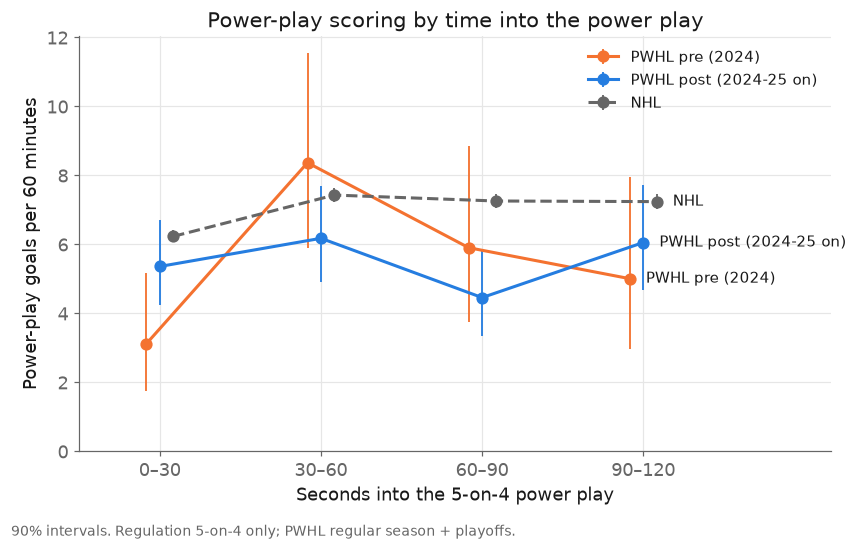

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
mid = (EDGES[:-1] + EDGES[1:]) / 2
for i, g in enumerate(GROUPS):
    t = timing[g]
    x = mid + (i - 1) * 2.5
    ax.errorbar(x, t["per60"], yerr=[t["per60"] - t["lo"], t["hi"] - t["per60"]], color=COLORS[g],
                marker="o", capsize=0, elinewidth=1.2, label=g, ls="-" if g != "NHL" else "--")
    ax.annotate(g, (x[-1] + 3, t["per60"].iloc[-1]), color=INK, va="center", fontsize=10)
ax.set_xticks(mid, [f"{a}–{b}" for a, b in zip(EDGES[:-1], EDGES[1:])])
ax.set_xlabel("Seconds into the 5-on-4 power play")
ax.set_ylabel("Power-play goals per 60 minutes")
ax.set_title("Power-play scoring by time into the power play")
ax.set_xlim(0, 140)
ax.set_ylim(bottom=0)
ax.legend(loc="upper right", fontsize=10)
fig.text(0.01, 0.01, "90% intervals. Regulation 5-on-4 only; PWHL regular season + playoffs.", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "eda_pp_goal_timing.png")
plt.show()

**Takeaway:** no visible spike at the start of PWHL power plays after the rule. The PWHL intervals are wide (a few dozen goals per bin), so a modest effect can't be ruled out. The next cell uses a sharper definition of "early".

### 1b. Before vs after the first stoppage

Under No Escape the penalty killers on the ice when the penalty is called must stay on through
the opening faceoff. The earliest the tired unit is guaranteed relief is the first stoppage, so
"early" = from the start of the power play up to the first faceoff after the opening one.

In [4]:
def early_late(df):
    fs = df["first_stoppage_s"].fillna(np.inf).to_numpy()
    a = df["spell_offset_s"].to_numpy()
    b = a + df["duration_s"].to_numpy()
    g = df["first_goal_for_s"].to_numpy()
    early_exp = np.clip(np.minimum(b, fs) - a, 0, None).sum()
    late_exp = np.clip(b - np.maximum(a, fs), 0, None).sum()
    early_g = int(((g > 0) & (g <= fs)).sum())
    late_g = int((g > fs).sum())
    re, rl = rate60(early_g, early_exp), rate60(late_g, late_exp)
    # rate ratio early/late with an exact conditional (binomial) interval
    n = early_g + late_g
    p, plo, phi = prop_ci(early_g, n)
    w = late_exp / early_exp
    ratio = (p / (1 - p)) * w
    return {"early_goals": early_g, "early_min": early_exp / 60, "early_per60": re[0],
            "late_goals": late_g, "late_min": late_exp / 60, "late_per60": rl[0],
            "share_goals_early": early_g / n,
            "rate_ratio": ratio, "ratio_lo": plo / (1 - plo) * w, "ratio_hi": phi / (1 - phi) * w}


el = pd.DataFrame({g: early_late(five4[five4["group"] == g]) for g in GROUPS}).T
el.round(2)

,early_goals,early_min,early_per60,late_goals,late_min,late_per60,share_goals_early,rate_ratio,ratio_lo,ratio_hi
PWHL pre (2024),42.0,470.07,5.36,28.0,290.00,5.79,0.60,0.93,0.60,1.43
PWHL post (2024-25 on),140.0,1368.67,6.14,70.0,891.42,4.71,0.67,1.30,1.02,1.68
NHL,9776.0,80179.27,7.32,5054.0,47637.88,6.37,0.66,1.15,1.12,1.18


**What this shows:** scoring before vs after the first stoppage, when the trapped penalty-killing unit is guaranteed relief. After the rule, PWHL power plays score faster before the first stoppage than after (rate ratio above 1, interval just clearing 1); before the rule the ratio was about 1. The NHL ratio is also above 1, so part of this happens anyway. **For the model:** keep an early/late hazard, with a modest effect centered near the NHL value, not a large No Escape spike.

### 1c. Power-play rates by season and the 4-on-3 multiplier

The plan estimates PWHL overtime power plays as `r × team 5-on-4 rate`, with
`r = rate(4v3 in OT) / rate(5v4 in regulation)` from the NHL. Is `r` stable across seasons?

In [5]:
nhl = pp[(pp["league"] == "NHL") & (pp["goals_complete"] == 1)]
rows = []
for season, g in nhl.groupby("season"):
    a = g[(g["in_ot"] == 0) & (g["strength"] == "5v4")]
    b = g[(g["in_ot"] == 1) & (g["strength"] == "4v3")]
    r5, r4 = rate60(a["goals_for"].sum(), a["duration_s"].sum()), rate60(b["goals_for"].sum(), b["duration_s"].sum())
    rows.append((season, a["goals_for"].sum(), a["duration_s"].sum() / 60, *r5,
                 b["goals_for"].sum(), b["duration_s"].sum() / 60, *r4))
nhl_rates = pd.DataFrame(rows, columns=["season", "g_5v4", "min_5v4", "per60_5v4", "lo_5v4", "hi_5v4",
                                        "g_4v3", "min_4v3", "per60_4v3", "lo_4v3", "hi_4v3"])
nhl_rates["r"] = nhl_rates["per60_4v3"] / nhl_rates["per60_5v4"]


def ratio_ci(g1, e1, g0, e0, level=0.90):
    """Ratio of two Poisson rates (g1/e1)/(g0/e0), exact conditional interval."""
    p, lo, hi = prop_ci(g1, g1 + g0, level)
    w = e0 / e1
    return p / (1 - p) * w, lo / (1 - lo) * w, hi / (1 - hi) * w


tot = nhl_rates.sum(numeric_only=True)
r_pooled = ratio_ci(tot["g_4v3"], tot["min_4v3"], tot["g_5v4"], tot["min_5v4"])
print("Pooled NHL 4v3/5v4 multiplier r =", fmt(*r_pooled))
nhl_rates.round(2)

Pooled NHL 4v3/5v4 multiplier r = 1.96 [1.75, 2.19]


,season,g_5v4,min_5v4,per60_5v4,lo_5v4,hi_5v4,g_4v3,min_4v3,per60_4v3,lo_4v3,hi_4v3,r
0,2015-16,1313,12286.98,6.41,6.12,6.71,25,118.50,12.66,8.80,17.68,1.97
1,2016-17,1284,11825.95,6.51,6.22,6.82,23,107.43,12.85,8.78,18.20,1.97
2,2017-18,1448,12279.37,7.08,6.77,7.39,15,86.32,10.43,6.43,16.06,1.47
3,2018-19,1361,11976.25,6.82,6.52,7.13,22,86.43,15.27,10.34,21.81,2.24
4,2019-20,1130,10557.75,6.42,6.11,6.75,20,84.62,14.18,9.40,20.61,2.21
5,2020-21,936,8263.10,6.80,6.44,7.17,11,56.72,11.64,6.53,19.26,1.71
6,2021-22,1459,12053.57,7.26,6.95,7.58,17,79.32,12.86,8.19,19.29,1.77
7,2022-23,1571,12691.23,7.43,7.12,7.74,28,107.02,15.70,11.16,21.52,2.11
8,2023-24,1543,12458.58,7.43,7.12,7.75,22,96.78,13.64,9.23,19.48,1.84
9,2024-25,1413,11380.67,7.45,7.13,7.78,24,65.42,22.01,15.18,30.96,2.95


**What this shows:** NHL 5-on-4 rates in regulation and 4-on-3 rates in overtime, season by season, and their ratio `r`. The 5-on-4 rate is very stable; the 4-on-3 rate is noisier (about 100 minutes a season) but its ratio to 5-on-4 stays near 2 in every season except a noisy 2024-25.

In [6]:
pw = pp[(pp["league"] == "PWHL") & (pp["season_type"] != "preseason")]
rows = []
for season, g in pw.groupby("season"):
    a = g[(g["in_ot"] == 0) & (g["strength"] == "5v4")]
    rows.append((season, a["goals_for"].sum(), a["duration_s"].sum() / 60, *rate60(a["goals_for"].sum(), a["duration_s"].sum())))
pwhl_rates = pd.DataFrame(rows, columns=["season", "goals", "minutes", "per60", "lo", "hi"])
print("PWHL 5-on-4 goals per 60 by season (regular + playoffs):")
pwhl_rates.round(2)

PWHL 5-on-4 goals per 60 by season (regular + playoffs):


,season,goals,minutes,per60,lo,hi
0,2024,70,760.07,5.53,4.49,6.74
1,2024-25,94,919.82,6.13,5.13,7.28
2,2025,11,84.92,7.77,4.36,12.86
3,2025-26,98,1137.42,5.17,4.34,6.11
4,2026,8,117.93,4.07,2.03,7.34


**What this shows:** PWHL 5-on-4 scoring by season. Rates sit a little below the NHL's. The playoff rows (2025, 2026) are small samples.

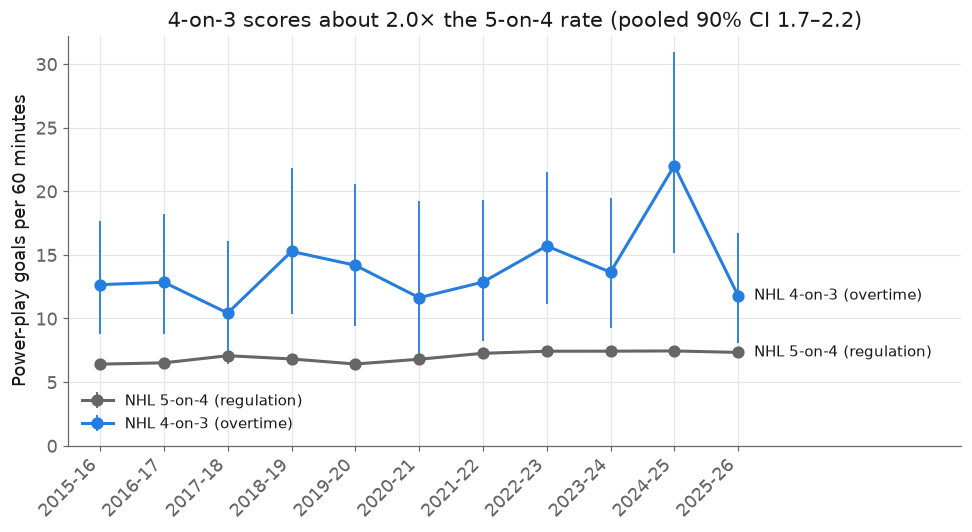

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(nhl_rates))
for col, color, label in (("5v4", MUTED, "NHL 5-on-4 (regulation)"), ("4v3", BLUE, "NHL 4-on-3 (overtime)")):
    y = nhl_rates[f"per60_{col}"]
    ax.errorbar(x, y, yerr=[y - nhl_rates[f"lo_{col}"], nhl_rates[f"hi_{col}"] - y], color=color, marker="o",
                elinewidth=1.2, label=label)
    ax.annotate(label, (x[-1] + 0.25, y.iloc[-1]), va="center", fontsize=10)
ax.set_xticks(x, nhl_rates["season"], rotation=45, ha="right")
ax.set_ylabel("Power-play goals per 60 minutes")
ax.set_ylim(bottom=0)
ax.set_xlim(-0.5, len(x) + 2.5)
ax.set_title(f"4-on-3 scores about {r_pooled[0]:.1f}× the 5-on-4 rate (pooled 90% CI {r_pooled[1]:.1f}–{r_pooled[2]:.1f})")
ax.legend(loc="lower left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "eda_4v3_vs_5v4.png")
plt.show()

**Takeaway:** a 4-on-3 in overtime scores about twice as often per minute as a regulation 5-on-4, and the multiplier is stable across 11 seasons. This is a solid input for the PWHL overtime power-play rate.

### 1d. Team differences in PWHL 5-on-4 scoring

Do teams differ more than chance? A Poisson dispersion test on team goals given minutes
(2024-25 on, regular season + playoffs) tells us whether team-level rates are worth modeling.

In [8]:
post = pw[(pw["in_ot"] == 0) & (pw["strength"] == "5v4") & (pw["no_escape"] == 1)]
team = post.groupby("team").agg(goals=("goals_for", "sum"), seconds=("duration_s", "sum"))
league_rate = team["goals"].sum() / team["seconds"].sum()
team["expected"] = team["seconds"] * league_rate
team["per60"] = team["goals"] / team["seconds"] * 3600
chi2 = (((team["goals"] - team["expected"]) ** 2) / team["expected"]).sum()
dof = len(team) - 1
print(f"Dispersion chi2 = {chi2:.1f} on {dof} df, p = {stats.chi2.sf(chi2, dof):.3f}")
team.sort_values("per60", ascending=False).round(2)

Dispersion chi2 = 7.2 on 7 df, p = 0.412


,goals,seconds,expected,per60
team,,,,
MIN,42,20921.0,32.55,7.23
TOR,31,15955.0,24.83,6.99
MTL,33,21270.0,33.10,5.59
SEA,13,8799.0,13.69,5.32
NY,30,20857.0,32.45,5.18
OTT,29,20333.0,31.64,5.13
BOS,25,19646.0,30.57,4.58
VAN,8,7824.0,12.17,3.68


**What this shows:** whether PWHL teams' 5-on-4 scoring differs more than chance would produce. The test is far from significant: the spread in team rates is about what random variation gives. **For the model:** use a league-wide power-play rate with only light, shrunk team adjustments; team-specific results would mostly reflect noise.

### 1e. Reconciling the overtime power-play rate with Rachman (29.4%)

Our 8 power plays created by OT penalties scored twice (25%). Rachman's all-time rate may also
count power plays carried into OT from regulation. Count every PWHL regular-season power play
with any OT time, and those that started in OT with at least 2:00 left (a full power play was
available; counting power plays that *lasted* 2:00 would only keep the ones that didn't score).

In [9]:
ot_pp = pp[(pp["league"] == "PWHL") & (pp["season_type"] == "regular") & (pp["in_ot"] == 1)]
spells = ot_pp.groupby(["game_id", "spell"]).agg(
    goals=("goals_for", "sum"), ot_seconds=("duration_s", "sum"), spell_start=("spell_start_s", "first"))
spells["started_in_ot"] = spells["spell_start"] >= 3600
full_avail = spells["started_in_ot"] & (spells["spell_start"] <= 3900 - 120)
summary = pd.DataFrame({
    "spells": [len(spells), spells["started_in_ot"].sum(), (~spells["started_in_ot"]).sum(), full_avail.sum()],
    "scored": [(spells["goals"] > 0).sum(), (spells.loc[spells["started_in_ot"], "goals"] > 0).sum(),
               (spells.loc[~spells["started_in_ot"], "goals"] > 0).sum(), (spells.loc[full_avail, "goals"] > 0).sum()],
}, index=["all OT power plays", "started in OT", "carried in from regulation", "started in OT with 2:00+ left"])
summary["rate"] = summary["scored"] / summary["spells"]
summary

,spells,scored,rate
all OT power plays,16,5,0.312500
started in OT,9,3,0.333333
carried in from regulation,7,2,0.285714
started in OT with 2:00+ left,6,3,0.500000


**What this shows:** our count of PWHL regular-season power plays with overtime time, to compare with Rachman (29.4% all-time, 50% with a full 2:00). Counting power plays carried over from regulation, our rates match hers closely; the small gap is likely one power play counted differently. Power plays with a full 2:00 available score far more often, a first sign that time remaining drives the decision.

## 2. Penalty shot

### 2a. Success rates by league and attempt type

In [10]:
reg = so[so["season_type"] != "preseason"]
rows = []
for (league, ps), g in reg.groupby(["league", "is_penalty_shot"]):
    rows.append((league, "penalty shot" if ps else "shootout", len(g), g["goal"].sum(), *prop_ci(g["goal"].sum(), len(g))))
succ = pd.DataFrame(rows, columns=["league", "type", "attempts", "goals", "rate", "lo", "hi"])
succ.round(3)

,league,type,attempts,goals,rate,lo,hi
0,NHL,shootout,7303,2302,0.315,0.306,0.324
1,NHL,penalty shot,467,132,0.283,0.248,0.319
2,PWHL,shootout,287,88,0.307,0.262,0.354
3,PWHL,penalty shot,9,1,0.111,0.006,0.429


**What this shows:** conversion rates by league and attempt type. PWHL and NHL shootouts convert at almost the same rate, so the NHL fit is a good prior. NHL in-game penalty shots convert a little less often than shootout attempts (a small negative δ). The PWHL has only 9 in-game penalty shots, too few to say anything on their own.

In [11]:
by_season = (reg[reg["is_penalty_shot"] == 0].groupby(["league", "season"])["goal"]
             .agg(attempts="size", rate="mean").round(3))
by_season

attempts   rate
league season                  
NHL    2015-16       742  0.321
       2016-17       713  0.314
       2017-18       783  0.309
       2018-19       639  0.294
       2019-20       621  0.322
       2020-21       448  0.324
       2021-22       747  0.300
       2022-23       670  0.337
       2023-24       617  0.295
       2024-25       513  0.329
       2025-26       810  0.326
PWHL   2024           66  0.318
       2024-25       109  0.294
       2025-26       112  0.312

**What this shows:** shootout success by season. No trend in either league; seasons vary within normal noise, so pooling seasons is fine.

### 2b. How many attempts per shooter and goalie?

PWHL: 287 attempts, 68 shooters (20 with 5+, 9 with 10+), 16 goalies (median 14 attempts faced)
NHL: 7303 attempts, 706 shooters (238 with 10+), 167 goalies


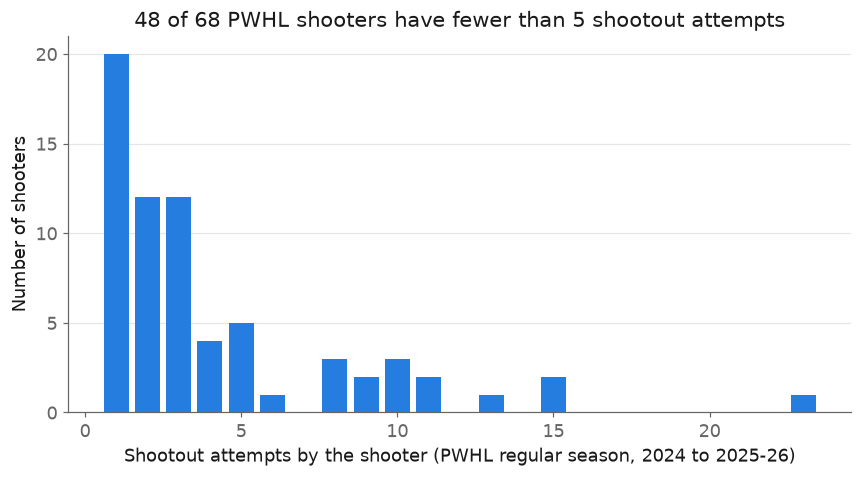

In [12]:
pw_so = reg[(reg["league"] == "PWHL") & (reg["is_penalty_shot"] == 0)]
shooter_n = pw_so["shooter_id"].value_counts()
goalie_n = pw_so["goalie_id"].value_counts()
print(f"PWHL: {len(pw_so)} attempts, {shooter_n.size} shooters "
      f"({(shooter_n >= 5).sum()} with 5+, {(shooter_n >= 10).sum()} with 10+), "
      f"{goalie_n.size} goalies (median {goalie_n.median():.0f} attempts faced)")
nh_so = reg[(reg["league"] == "NHL") & (reg["is_penalty_shot"] == 0)]
print(f"NHL: {len(nh_so)} attempts, {nh_so['shooter_id'].nunique()} shooters "
      f"({(nh_so['shooter_id'].value_counts() >= 10).sum()} with 10+), {nh_so['goalie_id'].nunique()} goalies")

fig, ax = plt.subplots(figsize=(8, 4.5))
counts = shooter_n.value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.set_xlabel("Shootout attempts by the shooter (PWHL regular season, 2024 to 2025-26)")
ax.set_ylabel("Number of shooters")
ax.set_title(f"{(shooter_n < 5).sum()} of {shooter_n.size} PWHL shooters have fewer than 5 shootout attempts")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "eda_attempts_per_shooter.png")
plt.show()

**Takeaway:** most PWHL shooters have only one to four shootout attempts. Their individual success rates mean little on their own, which is why the penalty-shot model must borrow strength (hierarchical shrinkage plus the NHL prior).

### 2c. How much of shootout success is skill? (split-half reliability)

For players with enough attempts, split each player's attempts randomly in two and correlate
the two halves' success rates across players; repeat 500 times and average. Spearman-Brown
gives the reliability of the full record. Near 0 = mostly luck; near 1 = mostly skill.

In [13]:
rng = np.random.default_rng(2027)


def split_half(df, id_col, min_n, reps=500):
    eligible = df.groupby(id_col).filter(lambda g: len(g) >= min_n)
    groups = [g["goal"].to_numpy() for _, g in eligible.groupby(id_col)]
    rs = []
    for _ in range(reps):
        h1, h2 = [], []
        for y in groups:
            perm = rng.permutation(y)
            half = len(y) // 2
            h1.append(perm[:half].mean())
            h2.append(perm[half:2 * half].mean())
        rs.append(np.corrcoef(h1, h2)[0, 1])
    r = float(np.nanmean(rs))
    return {"players": len(groups), "split_half_r": r, "spearman_brown": 2 * r / (1 + r)}


rel = pd.DataFrame({
    "NHL shooters (10+)": split_half(nh_so, "shooter_id", 10),
    "NHL goalies (30+)": split_half(nh_so, "goalie_id", 30),
    "PWHL shooters (6+)": split_half(pw_so, "shooter_id", 6),
    "PWHL goalies (10+)": split_half(pw_so, "goalie_id", 10),
}).T
rel.round(3)

,players,split_half_r,spearman_brown
NHL shooters (10+),238.0,0.059,0.112
NHL goalies (30+),90.0,0.195,0.326
PWHL shooters (6+),15.0,-0.019,-0.040
PWHL goalies (10+),11.0,0.024,0.047


**What this shows:** how repeatable shootout success is. NHL shooters' reliability is low (mostly luck, a little skill); PWHL shooters show none detectable (few players, few attempts). Goalies are more consistent than shooters. **For the model and poster:** expect heavy shrinkage, so differences between shooters will be small; goalie effects matter more. "Shootout success is mostly luck" is a possible headline.

### 2d. Round and home effects

In [14]:
def round_group(row):
    regulation_rounds = 5 if row["league"] == "PWHL" else 3
    if row["so_round"] == 1:
        return "1st"
    return "regulation rounds 2+" if row["so_round"] <= regulation_rounds else "sudden death"


so_only = reg[reg["is_penalty_shot"] == 0].copy()
so_only["round_group"] = so_only.apply(round_group, axis=1)
rnd = so_only.groupby(["league", "round_group"])["goal"].agg(attempts="size", rate="mean").round(3)
home = so_only.groupby(["league", "is_home"])["goal"].agg(attempts="size", rate="mean").round(3)
display(rnd)
display(home)

attempts   rate
league round_group                          
NHL    1st                       2044  0.328
       regulation rounds 2+      3649  0.319
       sudden death              1610  0.291
PWHL   1st                         56  0.339
       regulation rounds 2+       207  0.280
       sudden death                24  0.458

attempts   rate
league is_home                 
NHL    0.0          3569  0.311
       1.0          3734  0.319
PWHL   0.0           142  0.261
       1.0           145  0.352

**What this shows:** success by round and for home vs away shooters. In the NHL, sudden-death rounds convert a bit less often (deeper, weaker shooters). The PWHL sudden-death and home/away differences are based on small samples and are likely noise; the model can include these terms with priors from the NHL.

## 3. Overtime

### 3a. 3-on-3 scoring rates

Pure 3-on-3 time only (both goalies in, no penalties). PWHL regular season, tied after regulation.

In [15]:
def ot_rate(df):
    games = df[df["is_home"] == 1]
    goals = int(df["gf_3v3"].sum())
    secs = games["toi_3v3_s"].sum()
    est = rate60(goals, secs)
    home_goals = int(games["gf_3v3"].sum())
    return {"games": len(games), "minutes": secs / 60, "goals": goals, "per60_both_teams": est[0],
            "lo": est[1], "hi": est[2], "home_share": home_goals / goals}


ot_reg = ot[(ot["season_type"] == "regular") & (ot["tied_after_reg"] == 1) & (ot["goals_complete"] == 1)]
ot_tab = pd.DataFrame({lg: ot_rate(ot_reg[ot_reg["league"] == lg]) for lg in ("PWHL", "NHL")}).T
ot_tab.round(3)

,games,minutes,goals,per60_both_teams,lo,hi,home_share
PWHL,77.0,238.817,43.0,10.803,8.244,13.931,0.326
NHL,2997.0,8249.950,1686.0,12.262,11.775,12.765,0.502


**What this shows:** 3-on-3 overtime scoring rates. The PWHL scores somewhat less often than the NHL at 3-on-3. In the PWHL, away teams scored about two thirds of OT goals, which taken at face value would mean playing at home hurts in overtime. With only 43 goals (and many comparisons in this notebook) that's most likely chance; NHL home teams score about half of OT goals. **For the model:** include a home-ice adjustment that starts at \"no home advantage\" and lets the PWHL data move it only as far as 43 goals justify. The estimate will land a little below 50%, not at the raw split, and will move further on its own if the pattern holds in future seasons.

### 3b. Is the OT goal hazard flat?

`W0(t)` assumes a constant scoring rate through overtime. For games tied after regulation,
rate OT goals by OT minute (all OT time, including power plays).

In [16]:
games_pw = pd.read_parquet(I / "pwhl_games.parquet")[["game_id", "season_type", "game_end_s"]].assign(league="PWHL")
games_nh = pd.read_parquet(I / "nhl_games.parquet")[["game_id", "game_end_s", "goals_complete"]].assign(league="NHL", season_type="regular")
games_pw["game_id"] = games_pw["game_id"].astype(str)
games_nh["game_id"] = games_nh["game_id"].astype(str)
g_all = pd.concat([games_pw, games_nh], ignore_index=True)
tied = ot_reg[ot_reg["is_home"] == 1][["league", "game_id", "gf_ot", "ga_ot"]].merge(g_all[["league", "game_id", "game_end_s"]])
tied["ot_len"] = (tied["game_end_s"] - 3600).clip(upper=300)
tied["scored"] = (tied["gf_ot"] + tied["ga_ot"]) > 0

rows = []
for lg in ("PWHL", "NHL"):
    t = tied[tied["league"] == lg]
    for m in range(5):
        lo, hi = 60 * m, 60 * (m + 1)
        exposure = np.clip(np.minimum(t["ot_len"], hi) - lo, 0, None).sum()
        goals = int((t["scored"] & (t["ot_len"] > lo) & (t["ot_len"] <= hi)).sum())
        rows.append((lg, f"{m}:00–{m + 1}:00", m, goals, exposure / 60, *rate60(goals, exposure)))
hazard = pd.DataFrame(rows, columns=["league", "ot_minute", "m", "goals", "minutes", "per60", "lo", "hi"])
hazard.round(2)

,league,ot_minute,m,goals,minutes,per60,lo,hi
0,PWHL,0:00–1:00,0,12,71.70,10.04,5.79,16.27
1,PWHL,1:00–2:00,1,10,60.90,9.85,5.35,16.71
2,PWHL,2:00–3:00,2,11,51.10,12.92,7.24,21.38
3,PWHL,3:00–4:00,3,8,40.32,11.91,5.92,21.48
4,PWHL,4:00–5:00,4,8,32.55,14.75,7.34,26.61
5,NHL,0:00–1:00,0,450,2817.93,9.58,8.85,10.36
6,NHL,1:00–2:00,1,469,2317.50,12.14,11.24,13.11
7,NHL,2:00–3:00,2,413,1869.25,13.26,12.20,14.38
8,NHL,3:00–4:00,3,340,1496.30,13.63,12.44,14.91
9,NHL,4:00–5:00,4,309,1181.10,15.70,14.26,17.25


**What this shows:** the OT scoring rate in each minute of overtime. In the NHL it climbs steadily from the first minute to the fifth; the PWHL follows a similar path with wide intervals.

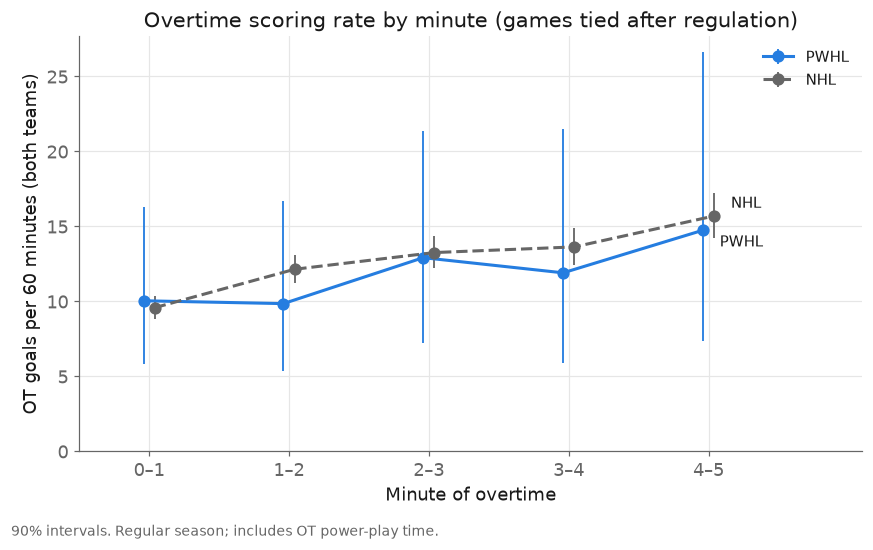

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (lg, color) in enumerate((("PWHL", BLUE), ("NHL", MUTED))):
    h = hazard[hazard["league"] == lg]
    x = h["m"] + 0.5 + (i - 0.5) * 0.08
    ax.errorbar(x, h["per60"], yerr=[h["per60"] - h["lo"], h["hi"] - h["per60"]], color=color, marker="o",
                elinewidth=1.2, label=lg, ls="-" if lg == "PWHL" else "--")
    ax.annotate(lg, (x.iloc[-1] + 0.12, h["per60"].iloc[-1]), xytext=(0, 8 if lg == "NHL" else -8),
                textcoords="offset points", va="center", fontsize=10)
ax.set_xticks(np.arange(5) + 0.5, [f"{m}–{m + 1}" for m in range(5)])
ax.set_xlabel("Minute of overtime")
ax.set_ylabel("OT goals per 60 minutes (both teams)")
ax.set_title("Overtime scoring rate by minute (games tied after regulation)")
ax.set_ylim(bottom=0)
ax.set_xlim(0, 5.6)
ax.legend(loc="upper right", fontsize=10)
fig.text(0.01, 0.01, "90% intervals. Regular season; includes OT power-play time.", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "eda_ot_hazard.png")
plt.show()

**Takeaway:** overtime scoring is not constant: it rises as overtime goes on (tired players, more open play). **For the model:** `W0(t)` needs a time-varying scoring rate, not the constant rate in the original plan. This is the most important model change from the exploration.

### 3c. When are OT penalties called?

In [18]:
calls = otp[(otp["season_type"] == "regular") & (otp["ps_awarded"] == 0) & (otp["coincidental"] == 0)].copy()
calls["ot_minute"] = (calls["ot_elapsed_s"] // 60).clip(upper=4).astype(int)
calls.groupby(["league", "ot_minute"]).size().unstack(fill_value=0)

ot_minute,0,1,2,3,4
league,,,,,
NHL,108,144,140,118,125
PWHL,0,2,3,2,1


**What this shows:** when overtime minors are called. NHL penalties are spread fairly evenly after the first minute (fewer in the first). The PWHL has only 8, too few to see a pattern. Every part of the break-even curve gets used in practice.

In [19]:
print("NHL OT power plays (created by an OT minor):")
nhl_otp = otp[(otp["league"] == "NHL") & (otp["pp_created"] == 1) & (otp["goals_complete"] == 1)]
print(" scored:", fmt(*prop_ci(nhl_otp["pp_goal"].sum(), len(nhl_otp)), pct=True), f"(n = {len(nhl_otp)})")
full = nhl_otp[nhl_otp["ot_remaining_s"] >= 120]
part = nhl_otp[nhl_otp["ot_remaining_s"] < 120]
print(" called with 2:00+ left:", fmt(*prop_ci(full["pp_goal"].sum(), len(full)), pct=True), f"(n = {len(full)})")
print(" called with under 2:00 left:", fmt(*prop_ci(part["pp_goal"].sum(), len(part)), pct=True), f"(n = {len(part)})")
print(" shorthanded goal against:", fmt(*prop_ci(nhl_otp["sh_goal"].sum(), len(nhl_otp)), pct=True))

NHL OT power plays (created by an OT minor):
 scored: 32.0% [28.8%, 35.3%] (n = 581)
 called with 2:00+ left: 38.4% [34.3%, 42.7%] (n = 380)
 called with under 2:00 left: 19.9% [15.4%, 25.1%] (n = 201)
 shorthanded goal against: 0.9% [0.3%, 1.8%]


**What this shows:** NHL overtime power plays by time left when the penalty was called. Power plays with 2:00 or more available score far more often than those called with under 2:00 left, and shorthanded goals are very rare. This is the time-remaining effect behind the break-even curve, visible directly in the data.

## 4. Sanity checks

In [20]:
pre = ot[(ot["league"] == "PWHL") & (ot["season_type"] == "preseason")]
print("PWHL preseason OT games:", pre["game_id"].nunique(), "| tied after regulation:",
      pre[pre["is_home"] == 1]["tied_after_reg"].sum())
nhl_all = pp[(pp["league"] == "NHL") & (pp["in_ot"] == 1) & (pp["strength"] == "4v3")]
for label, d in (("all games", nhl_all), ("goals_complete only", nhl_all[nhl_all["goals_complete"] == 1])):
    print(f"NHL OT 4v3 goals per 60, {label}:", fmt(*rate60(d["goals_for"].sum(), d["duration_s"].sum())))

PWHL preseason OT games: 11 | tied after regulation: 4
NHL OT 4v3 goals per 60, all games: 13.70 [12.25, 15.28]
NHL OT 4v3 goals per 60, goals_complete only: 13.72 [12.27, 15.31]


**What this shows:** most PWHL preseason overtimes were played without a tied score, so leaving preseason out of the overtime models was the right call. Excluding the NHL games that are missing a goal makes no difference to the 4-on-3 rate.

## 5. Summary: what this means for the models

These decisions are also recorded in `CONVENTIONS.md` ("Model decisions from exploration").

| Model | What we found | How we implement it |
|---|---|---|
| **Penalty shot** (Step 7) | PWHL and NHL shootouts convert at about the same rate. Shooter success is barely repeatable; goalies are more consistent. In-game penalty shots convert slightly less often than shootout attempts. Most PWHL shooters have under 5 attempts. | Fit the NHL first; use its posterior as the PWHL prior. Expect heavy shrinkage of shooters toward the league average, so "who should shoot" differences will be small and goalie effects matter more. Keep the in-game penalty-shot term (δ) with a slightly negative prior. Round and home terms only if they help in the holdout test. |
| **Power play** (Step 8) | The 4-on-3 multiplier is about 2 and stable across seasons. PWHL teams show no detectable 5-on-4 differences. The No Escape effect is modest. Shorthanded OT goals are rare. | OT power-play rate = league 5-on-4 rate × r (from the NHL), updated with PWHL OT power plays. League-level rate with a strongly shrunk team effect. Two-piece scoring rate within a power play (before / after the first stoppage), early/late ratio centered near the NHL value. Small shorthanded-goal rate. |
| **Overtime** (Step 8) | 3-on-3 scoring rises as overtime goes on, in both leagues. The PWHL scores a little less than the NHL. The PWHL home/away split is most likely noise. | `W0(t)` uses a time-varying scoring rate (shape from the NHL, level from the PWHL), computed numerically each second; this replaces the plan's constant rate. Home-ice term starts at "no advantage" and is only lightly updated. Shootout simulation unchanged. |
| **Decision and validation** (Steps 9-10) | NHL OT power plays called with 2:00+ left score much more often than those with under 2:00 left. Our PWHL rates reproduce Rachman's. | Break-even curve `p*(t)` as planned. The model must reproduce the NHL conversion split by time left and Rachman's PWHL rates. |

**Unchanged:** preseason stays out of the overtime models; NHL games missing a goal are excluded (no effect on rates); the holdout test runs as planned.